# FinMark Corporation: Data Visualization Workflow
## Milestone 2 — Team PETIX

### Analysis scope

**Problem to address:** Turn the cleaned FinMark project records into clear descriptive evidence that helps the team understand the data and decide what should be checked before future machine learning.

**Questions and requirements:** How are observed ages and valid transaction amounts distributed? How do transaction amounts vary across product categories? Are categories or sentiments imbalanced? What patterns appear over time or across variables? Which data-quality issues, unusual values, or limitations matter for future modeling?

**Scope:** This notebook summarizes three project datasets—customer demographics, transactions, and social-media interactions—with NumPy, Matplotlib, and Seaborn. It reports numerical distributions, compares variables and groups, examines recorded monthly counts, and interprets findings for future ML work.

**Constraints and limits:** The analysis uses the project’s prepared EDA CSV files, excludes records with unresolved primary-ID conflicts as documented by the project, uses observed rather than imputed ages, and includes zero but not missing or negative amounts in valid-amount analyses. Transaction rows are not independent when customers contribute multiple transactions. Date coverage may be incomplete. No target or prediction task has been defined, so this is not model training, forecasting, causal analysis, or a claim about predictive performance.

The charts and interpretation below are descriptive. They identify evidence and follow-up needs; they do not establish cause and effect.

## Reproducibility and setup

Run this notebook with `Week7_ML_Data_Visualizations` as the working folder so the relative `data_eda/` and `figures/` paths resolve. Install dependencies once in the selected Python environment from a terminal:

```bash
python -m pip install pandas numpy matplotlib seaborn openpyxl
```

Then select that same environment as the notebook kernel and run the cells in order. The install command is documentation, not an analysis cell, so running the notebook does not attempt to alter the environment.

## Data source, selection, and quality controls

### Source and selection

The project includes three original Excel workbooks in `data_raw/`: customer demographics, customer transactions, and social-media interactions. The Week 3 preprocessing workflow and Milestone 1 outputs provide the cleaned data and analysis-ready exports. This notebook reads the four CSVs in `data_eda/` so its charts use the same prepared records and decisions as the earlier EDA. The corresponding `data_audit/` files preserve records flagged for unresolved ID conflicts.

These files are the available project data, selected because they cover the requested customer, transaction, and social-media questions. The repository does not identify an external data provider, collection method, or collection date; therefore, source provenance and representativeness cannot be independently established here. The results should be interpreted as findings about these project records, not as estimates about a wider population.

### Checks and analysis decisions

- Inspected row counts, columns, and data types for every loaded analysis dataset.
- Kept unresolved primary-ID conflict records out of the EDA datasets and retained audit files for review.
- Used `AgeObserved` and excluded imputed ages from age distributions and comparisons. The observed-age subset has 2,615 records and no ages outside 18–100.
- Used nonmissing, nonnegative transaction amounts, retaining 28 zeros. The separate status analysis preserves 281 missing, 29 nonnumeric, and 33 negative values for review rather than silently treating them as valid amounts.
- Kept Unknown categories visible as unavailable information instead of merging them into known categories.
- Checked IQR-based potential outliers, but treated this as a screening rule rather than proof that records are correct.
- For linked age–amount analysis, reported unmatched and age-missing records and noted that customers can contribute multiple transactions.

These checks support transparent and repeatable analysis, but do not verify that source values are factually correct. Review flagged records and confirm the data dictionary/business meaning before modeling.

## Visualization design: question, chart, and alternatives

The chart type is chosen from the variable types and the question. Counts and percentages are labeled so viewers can tell which denominator a comparison uses.

| Analysis question | Chosen visual | Why it fits | Alternative considered and limitation |
|---|---|---|---|
| What do observed ages and valid amounts look like? | Histograms with readable intervals and numerical summaries | Shows frequency across a continuous numerical range; the mean and median are reported without overlapping reference lines | A mean-only bar hides the distribution and can conceal spread or unevenness |
| Which product categories have more transaction records? | Horizontal bar chart | Supports direct count comparisons and keeps category names readable | A pie chart makes close category shares harder to compare |
| How do amounts vary by product category? | Boxplots | Compares medians, spread, and potential outliers across groups | Group means alone hide spread and are sensitive to extreme values |
| How do recorded transaction counts change by month? | Monthly line chart with full-range and focused panels | Preserves chronological order while showing both sparse edges and variation in the main coverage period | A bar chart can work for short periods but makes the long monthly sequence visually heavier; neither chart proves business activity in uncovered months |
| How does sentiment mix vary across platforms, and category mix across payment methods? | Within-group percentage heatmaps | Normalizing within each platform or payment method supports composition comparisons when group sizes differ | Raw-count heatmaps confound group size with category mix |
| How are age and amount distributed together? | Hexbin density chart | Bins repeated integer ages and dense transactions into counts, avoiding overplotting | A point scatterplot hides repeated/overlapping records |
| What amount values need review? | Separate count panels for valid amounts and smaller review statuses | Prevents the large valid group from obscuring missing, nonnumeric, negative, and zero counts | One shared scale makes the small status groups difficult to see |
| Do observed ages differ across gender groups? | Boxplots | Makes group medians and spreads easy to compare | Overlapping histograms would be harder to compare directly |

These are descriptive design choices. No chart can establish causation, statistical significance, representativeness, or predictive value by itself.

## Recommended Charts for the Report

For a concise report, lead with these six figures:

1. **Observed age distribution** — summarizes the 2,615 observed, non-imputed ages.
2. **Transaction amount distribution** — summarizes the 2,642 nonnegative amounts, including zero.
3. **Monthly transaction counts** — shows date coverage patterns; do not interpret empty months or edge changes as business activity without coverage evidence.
4. **Sentiment composition by platform** — compares within-platform sentiment percentages and keeps Unknown separate.
5. **Product category mix by payment method** — compares within-method percentages; the observed association is weak, so describe the chart rather than claim a meaningful relationship.
6. **Transaction amount data status** — shows missing and review values separately from valid zero amounts.

Use the **amount-by-category boxplot** as a supporting figure for group medians, spread, and the IQR outlier check. Product-category counts and the age-versus-amount density plot can support specific questions. The age-by-gender boxplot is supplementary: the groups overlap substantially. All charts are descriptive and use the subsets stated in their titles or notes.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set a consistent style for our charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")
print("Current folder:", Path.cwd())

All libraries imported successfully!
Current folder: E:\m4ml\H3101-ML-ml-linear-algebra-project-Team-PETIX-\H3101-ML-ml-linear-algebra-project-Team-PETIX--main\Week7_ML_Data_Visualizations


In [7]:
# Locate the analysis datasets
data_folder = Path.cwd() / "data_eda"

if not data_folder.is_dir():
    raise FileNotFoundError(
        f"Cannot find data_eda in {Path.cwd()}. Check the project folder."
    )

# Load the MS1 analysis datasets
demographics = pd.read_csv(
    data_folder / "customer_demographics_eda.csv"
)
transactions = pd.read_csv(
    data_folder / "customer_transactions_eda.csv"
)
amount_data = pd.read_csv(
    data_folder / "customer_transactions_amount_eda.csv"
)
social_media = pd.read_csv(
    data_folder / "social_media_interactions_eda.csv"
)

In [8]:
# Group the loaded datasets
datasets = {
    "Demographics": demographics,
    "Transactions": transactions,
    "Valid transaction amounts": amount_data,
    "Social media": social_media,
}

# Inspect dataset sizes, column names, and data types
for name, df in datasets.items():
    print(f"\n{name} — {len(df):,} rows")
    print(df.dtypes.to_string())


Demographics — 2,977 rows
CustomerID         str
Age            float64
Gender             str
Location           str
IncomeLevel        str
SignupDate         str
IDConflict        bool
AgeOriginal        str
AgeStatus          str
AgeObserved    float64
AgeImputed        bool

Transactions — 2,985 rows
CustomerID             str
TransactionID          str
TransactionDate        str
Amount             float64
ProductCategory        str
PaymentMethod          str
IDConflict            bool
AmountOriginal         str
AmountStatus           str

Valid transaction amounts — 2,642 rows
CustomerID             str
TransactionID          str
TransactionDate        str
Amount             float64
ProductCategory        str
PaymentMethod          str
IDConflict            bool
AmountOriginal     float64
AmountStatus           str

Social media — 2,980 rows
CustomerID            str
InteractionID         str
InteractionDate       str
Platform              str
InteractionType       str
Sentiment 

In [9]:
# Use observed ages and the separate valid-amount dataset
ages = demographics["AgeObserved"].dropna().to_numpy()
amounts = amount_data["Amount"].dropna().to_numpy()

print("Observed ages:", len(ages))
print("Valid amounts:", len(amounts))
print("Social media records:", len(social_media))

print("Ages outside 18–100:", np.sum((ages < 18) | (ages > 100)))
print("Negative amounts:", np.sum(amounts < 0))
print("Zero amounts retained:", np.sum(amounts == 0))

Observed ages: 2615
Valid amounts: 2642
Social media records: 2980
Ages outside 18–100: 0
Negative amounts: 0
Zero amounts retained: 28


In [10]:
# Numerical summaries using NumPy
def numerical_summary(values):
    q1, q3 = np.percentile(values, [25, 75])

    return {
        "Count": len(values),
        "Mean": np.mean(values),
        "Median": np.median(values),
        "Standard deviation (sample)": np.std(values, ddof=1),
        "Variance (sample)": np.var(values, ddof=1),
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "Range": np.ptp(values),
        "25th percentile (Q1)": q1,
        "75th percentile (Q3)": q3,
        "Interquartile range (IQR)": q3 - q1,
    }

numerical_stats = pd.DataFrame({
    "Observed Age": numerical_summary(ages),
    "Valid Amount": numerical_summary(amounts),
})

display(numerical_stats.round(2))

,Observed Age,Valid Amount
Count,2615.00,2642.00
Mean,44.59,499.03
Median,45.00,503.66
Standard deviation (sample),15.42,292.46
Variance (sample),237.81,85533.17
Minimum,18.00,0.00
Maximum,70.00,999.86
Range,52.00,999.86
25th percentile (Q1),31.00,237.98
75th percentile (Q3),58.00,749.18


## Additional NumPy Distribution Analysis

The summaries above describe center and spread. The next cell adds numerical distribution measures and frequency tables for the analysis subsets: observed ages and valid nonnegative transaction amounts. Age bands use the full observed range; transaction amounts use ten equal-width bins. Skewness and excess kurtosis use standardized population central moments, while potential outliers are counted with the 1.5 × IQR rule. These are descriptive checks, not data removal rules.

In [11]:
# Additional distribution measures using NumPy
def distribution_metrics(values):
    values = np.asarray(values, dtype=float)
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    centered = values - np.mean(values)
    second_moment = np.mean(centered ** 2)

    if second_moment == 0:
        skewness = np.nan
        excess_kurtosis = np.nan
    else:
        skewness = np.mean(centered ** 3) / second_moment ** 1.5
        excess_kurtosis = (
            np.mean(centered ** 4) / second_moment ** 2
        ) - 3

    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    return {
        "5th percentile": np.percentile(values, 5),
        "25th percentile": q1,
        "Median": median,
        "75th percentile": q3,
        "95th percentile": np.percentile(values, 95),
        "Skewness (moment)": skewness,
        "Excess kurtosis (moment)": excess_kurtosis,
        "IQR lower fence": lower_fence,
        "IQR upper fence": upper_fence,
        "Potential IQR outliers": np.count_nonzero(
            (values < lower_fence) | (values > upper_fence)
        ),
    }

additional_stats = pd.DataFrame({
    "Observed Age": distribution_metrics(ages),
    "Valid Amount": distribution_metrics(amounts),
})

print("Percentiles, distribution shape, and IQR outlier counts:")
display(additional_stats.round(3))

# Frequency distributions: age intervals span the observed 18–70 range.
age_bin_edges = np.array([17.5, 29.5, 39.5, 49.5, 59.5, 70.5])
age_counts, age_edges = np.histogram(ages, bins=age_bin_edges)
age_distribution = pd.DataFrame({
    "Age interval": ["18–29", "30–39", "40–49", "50–59", "60–70"],
    "Count": age_counts,
    "Percent": age_counts / len(ages) * 100,
})
print("Observed age distribution by interval:")
display(age_distribution.round(2))

# Ten equal-width bins summarize the valid amount distribution.
amount_counts, amount_edges = np.histogram(amounts, bins=10)
amount_labels = [
    f"{left:.2f} to {right:.2f}"
    for left, right in zip(amount_edges[:-1], amount_edges[1:])
]
amount_distribution = pd.DataFrame({
    "Amount interval": amount_labels,
    "Count": amount_counts,
    "Percent": amount_counts / len(amounts) * 100,
})
print("Valid transaction amount distribution (10 equal-width bins):")
display(amount_distribution.round(2))

print(
    "Zero amount records:",
    int(np.count_nonzero(amounts == 0)),
    f"({np.mean(amounts == 0) * 100:.2f}% of valid amounts)"
)


Percentiles, distribution shape, and IQR outlier counts:


,Observed Age,Valid Amount
5th percentile,20.000,46.776
25th percentile,31.000,237.985
Median,45.000,503.665
75th percentile,58.000,749.180
95th percentile,68.000,958.449
Skewness (moment),-0.059,0.015
Excess kurtosis (moment),-1.220,-1.207
IQR lower fence,-9.500,-528.807
IQR upper fence,98.500,1515.972
Potential IQR outliers,0.000,0.000


Observed age distribution by interval:


,Age interval,Count,Percent
0,18–29,584,22.33
1,30–39,466,17.82
2,40–49,476,18.20
3,50–59,513,19.62
4,60–70,576,22.03


Valid transaction amount distribution (10 equal-width bins):


,Amount interval,Count,Percent
0,0.00 to 99.99,268,10.14
1,99.99 to 199.97,277,10.48
2,199.97 to 299.96,271,10.26
3,299.96 to 399.94,251,9.50
4,399.94 to 499.93,247,9.35
5,499.93 to 599.92,286,10.83
6,599.92 to 699.90,244,9.24
7,699.90 to 799.89,266,10.07
8,799.89 to 899.87,243,9.20
9,899.87 to 999.86,289,10.94


Zero amount records: 28 (1.06% of valid amounts)


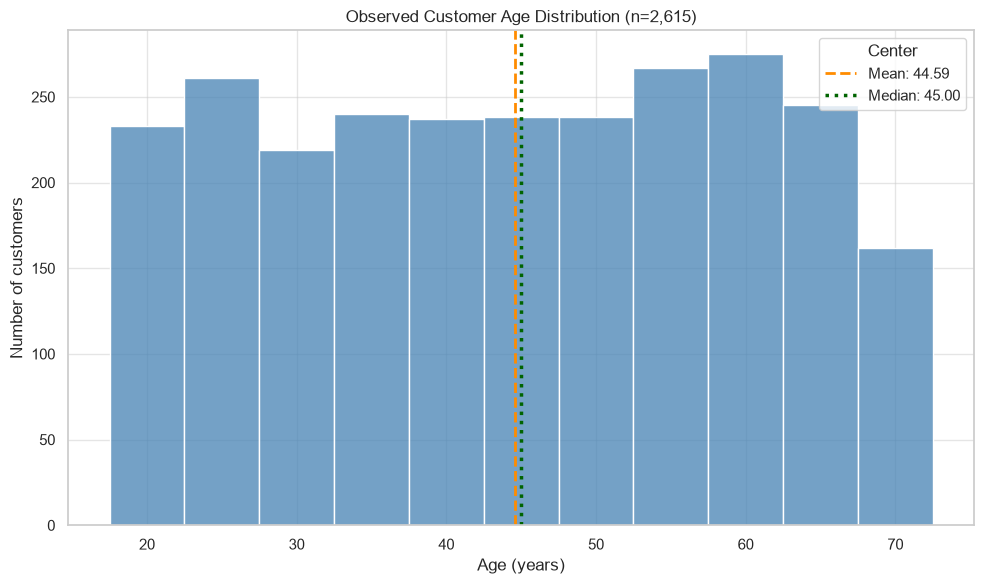

In [36]:
# Plot observed ages with mean and median reference lines.
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(
    x=ages,
    bins=np.arange(17.5, 73, 5),
    color="steelblue",
    edgecolor="white",
    ax=ax,
)

ax.axvline(
    np.mean(ages),
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {np.mean(ages):.2f}",
)
ax.axvline(
    np.median(ages),
    color="darkgreen",
    linestyle=":",
    linewidth=2.5,
    label=f"Median: {np.median(ages):.2f}",
)

ax.set_title(f"Observed Customer Age Distribution (n={len(ages):,})")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of customers")
ax.legend(title="Center")
fig.tight_layout()
fig.savefig(
    figures_folder / "01_observed_age_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Observed Age Distribution

A histogram was used to show how customer ages are distributed across
five-year intervals. The analysis includes 2,615 observed ages and excludes
median-imputed ages.

Observed ages range from 18 to 70, with a mean of 44.59 and a median of 45.
The 58–62 interval has the highest count at 275 customers (10.52%).
The complete five-year intervals have relatively similar counts, with no
single interval strongly dominating.

The final interval, 68–72, contains observed ages only from 68 to 70,
which should be considered when comparing its lower count.

For future machine learning, this chart helps assess age coverage.
It does not establish whether age predicts customer behavior.

In [13]:
# Count observations in the same intervals used in the histogram
age_bins = np.arange(17.5, 73, 5)
counts, edges = np.histogram(ages, bins=age_bins)

age_frequency = pd.DataFrame({
    "Age interval": [
        f"{int(left + 0.5)}–{int(right - 0.5)}"
        for left, right in zip(edges[:-1], edges[1:])
    ],
    "Count": counts,
    "Percentage": np.round(counts / len(ages) * 100, 2)
})

display(age_frequency)

,Age interval,Count,Percentage
0,18–22,233,8.91
1,23–27,261,9.98
2,28–32,219,8.37
3,33–37,240,9.18
4,38–42,237,9.06
5,43–47,238,9.10
6,48–52,238,9.10
7,53–57,267,10.21
8,58–62,275,10.52
9,63–67,245,9.37


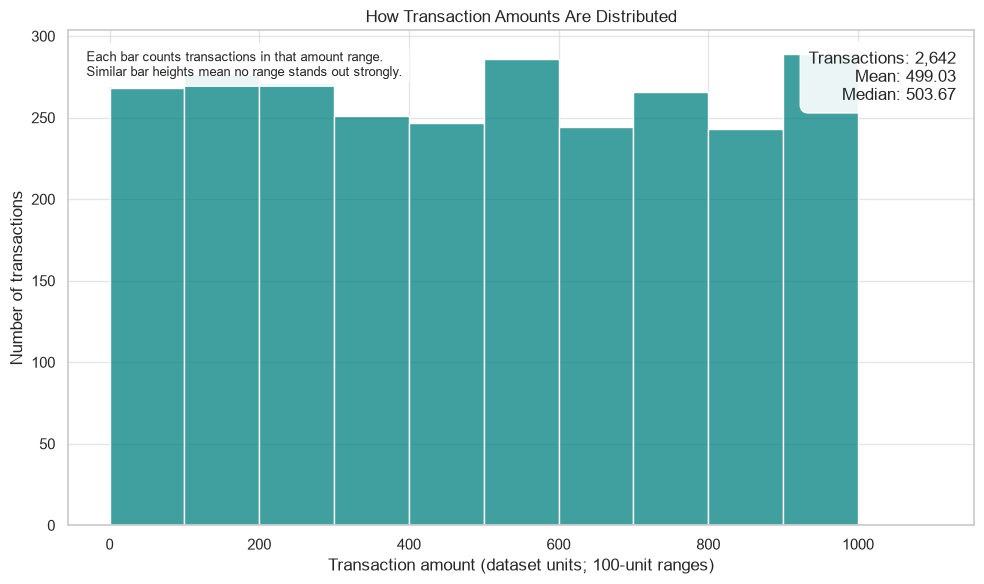

In [46]:
# Show how many valid transactions fall into each 100-unit amount range.
# Mean and median are reported as summary values instead of overlapping lines.
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(
    x=amounts,
    bins=np.arange(0, 1101, 100),
    color="teal",
    edgecolor="white",
    ax=ax,
)

mean_amount = np.mean(amounts)
median_amount = np.median(amounts)
summary = (
    f"Transactions: {len(amounts):,}" + chr(10)
    + f"Mean: {mean_amount:.2f}" + chr(10)
    + f"Median: {median_amount:.2f}"
)
ax.text(
    0.98, 0.96, summary,
    transform=ax.transAxes,
    ha="right",
    va="top",
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "alpha": 0.9},
)
ax.set_title("How Transaction Amounts Are Distributed")
ax.set_xlabel("Transaction amount (dataset units; 100-unit ranges)")
ax.set_ylabel("Number of transactions")
note = (
    "Each bar counts transactions in that amount range." + chr(10)
    + "Similar bar heights mean no range stands out strongly."
)
ax.text(
    0.02, 0.96, note,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "alpha": 0.9},
)
fig.tight_layout()
fig.savefig(
    figures_folder / "02_transaction_amount_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Transaction Amount Distribution

A histogram was used to examine the distribution of 2,642 nonmissing,
nonnegative transaction amounts. Zero amounts were retained.

Amounts range from 0 to 999.86 dataset units. The mean is 499.03,
the median is 503.66, and the sample standard deviation is 292.46.

The amounts are spread relatively evenly across the displayed intervals.
Although the mean and median are near 500, this does not mean that most
transactions are concentrated around that amount.

For future machine learning, the spread of transaction amounts can help
inform decisions about scaling numerical features. The chart alone does
not establish which amounts are unusual or incorrect.

,Count,Percentage
ProductCategory,,
Clothing,565,18.93
Electronics,558,18.69
Automotive,536,17.96
Home & Garden,528,17.69
Health & Beauty,520,17.42
Unknown,278,9.31


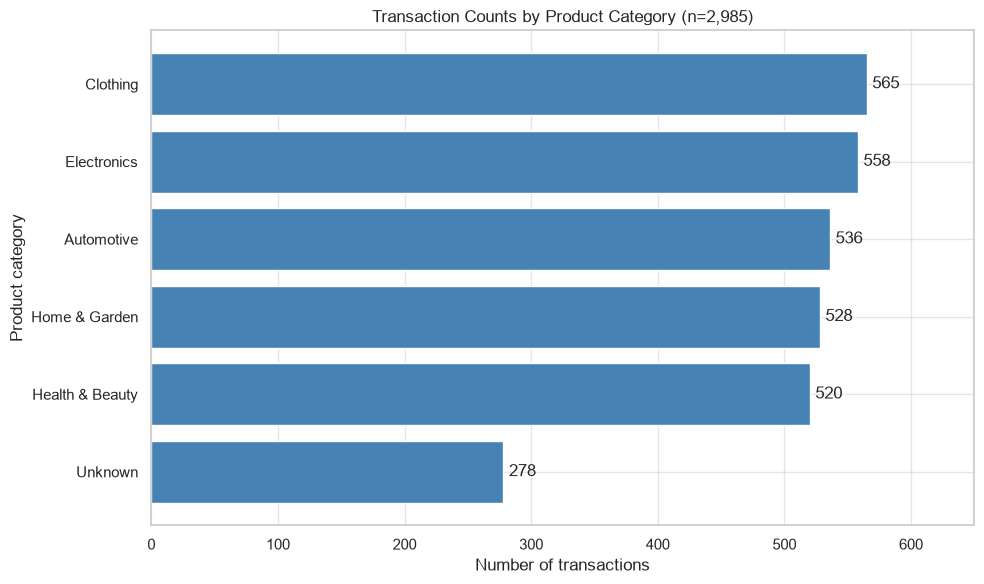

In [15]:
# Count transactions per product category
category_counts = (
    transactions["ProductCategory"]
    .fillna("Unknown")
    .value_counts()
)

display(pd.DataFrame({
    "Count": category_counts,
    "Percentage": (category_counts / len(transactions) * 100).round(2)
}))

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    category_counts.index,
    category_counts.values,
    color="steelblue"
)
ax.invert_yaxis()

ax.bar_label(ax.containers[0], padding=4)
ax.set_xlim(0, category_counts.max() * 1.15)
ax.set_title(f"Transaction Counts by Product Category (n={len(transactions):,})")
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Product category")

fig.tight_layout()
fig.savefig(
    figures_folder / "03_product_category_counts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Product Category Counts

A horizontal bar chart was used to compare transaction counts across
product categories. It includes all 2,985 transaction records in the
analysis dataset.

Clothing has the highest count at 565 transactions (18.93%), followed
by Electronics with 558 (18.69%). The five named categories have similar
counts, ranging from 520 to 565, so no named category strongly dominates.

Unknown accounts for 278 transactions (9.31%). This represents records
without an available category label and should be considered separately
when interpreting product preferences.

For future machine learning, these counts help assess category balance
and highlight missing category information. They describe transaction
frequency rather than total spending or individual customer preferences.

,count,median,mean
ProductCategory,,,
Home & Garden,469,524.62,525.16
Automotive,479,519.57,504.45
Electronics,492,510.75,494.53
Clothing,498,507.66,500.67
Health & Beauty,455,466.14,478.96
Unknown,249,461.82,481.64


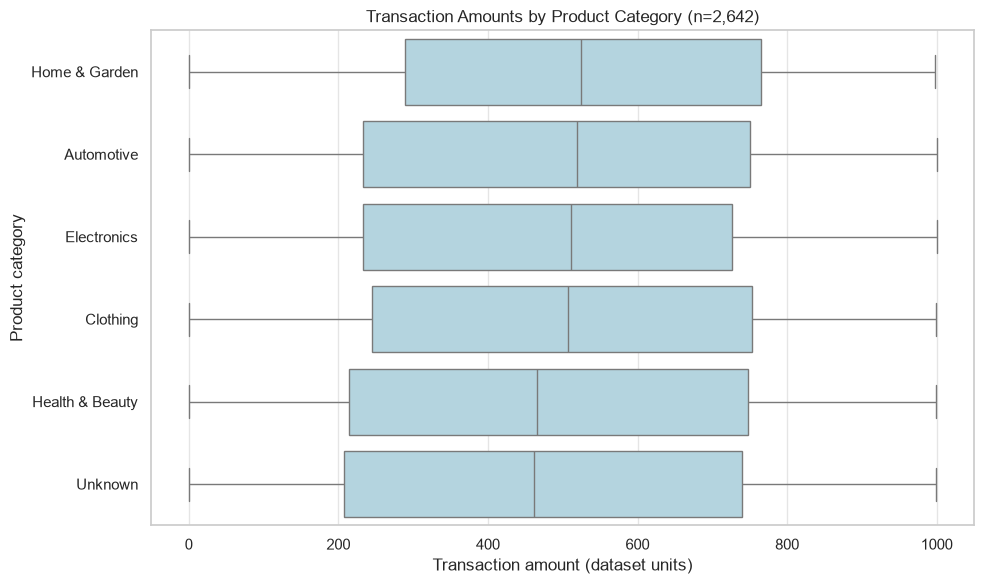

In [16]:
# Use only records with valid amounts
plot_data = amount_data.copy()
plot_data["ProductCategory"] = (
    plot_data["ProductCategory"].fillna("Unknown")
)

# Show the supporting counts and statistics
category_summary = (
    plot_data.groupby("ProductCategory")["Amount"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(category_summary.round(2))

# Compare amount distributions
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=plot_data,
    x="Amount",
    y="ProductCategory",
    order=category_summary.index,
    color="lightblue",
    whis=1.5,
    ax=ax
)

ax.set_title(
    f"Transaction Amounts by Product Category (n={len(plot_data):,})"
)
ax.set_xlabel("Transaction amount (dataset units)")
ax.set_ylabel("Product category")

fig.tight_layout()
fig.savefig(
    figures_folder / "04_amount_by_product_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Transaction Amounts by Product Category

A box plot was used to compare median transaction amounts, their spread,
and potential outliers across product categories. This chart uses the
2,642 records with nonmissing, nonnegative amounts.

Home & Garden has the highest median amount at 524.62 dataset units.
Health & Beauty has the lowest median among the named categories at
466.14. The Unknown group has a median of 461.82.

The boxes and whiskers overlap considerably, showing that transaction
amounts vary widely within each category. Differences in medians alone
do not establish that product category strongly predicts transaction amount.

The separate numerical check found no outliers within any category
using the 1.5 × IQR rule. This does not guarantee that every record is
accurate; it means no amounts exceeded the thresholds used.

For future machine learning, product category can be explored alongside
other variables, with its usefulness assessed through model evaluation.

In [17]:
# Check potential outliers within each product category
outlier_results = []

for category, group in plot_data.groupby("ProductCategory"):
    values = group["Amount"].to_numpy()
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = (values < lower) | (values > upper)

    outlier_results.append({
        "Product category": category,
        "Lower fence": lower,
        "Upper fence": upper,
        "Potential outliers": np.sum(flagged)
    })

display(pd.DataFrame(outlier_results).round(2))

,Product category,Lower fence,Upper fence,Potential outliers
0,Automotive,-544.17,1527.94,0
1,Clothing,-517.89,1515.95,0
2,Electronics,-506.69,1466.66,0
3,Health & Beauty,-585.10,1547.20,0
4,Home & Garden,-423.68,1478.04,0
5,Unknown,-590.65,1538.20,0


In [31]:
# Convert exported date strings back into dates
transactions["TransactionDate"] = pd.to_datetime(
    transactions["TransactionDate"],
    errors="coerce"
)

print("Total transaction records:", len(transactions))
print("Missing or unparseable dates:",
      transactions["TransactionDate"].isna().sum())
print("Earliest date:", transactions["TransactionDate"].min())
print("Latest date:", transactions["TransactionDate"].max())

# Count records by month
monthly_counts = (
    transactions.dropna(subset=["TransactionDate"])
    .groupby(transactions["TransactionDate"].dt.to_period("M"))
    .size()
)

display(monthly_counts.rename("Transaction count").to_frame())

Total transaction records: 2985
Missing or unparseable dates: 0
Earliest date: 2022-01-07 00:00:00
Latest date: 2024-12-06 00:00:00


,Transaction count
TransactionDate,
2022-01,3
2022-03,1
2022-04,1
2022-05,1
2022-06,1
2022-07,113
2022-08,109
2022-09,119
2022-10,120


In [19]:
# Inspect dates outside the main concentration of records
outside_main_period = transactions.loc[
    (transactions["TransactionDate"] < "2022-07-01")
    | (transactions["TransactionDate"] >= "2024-07-01"),
    ["TransactionID", "TransactionDate"]
].sort_values("TransactionDate")

display(outside_main_period)
print("Records outside the main period:", len(outside_main_period))

,TransactionID,TransactionDate
2379,aee21c96-febd-4906-9881-12e32030e7f4,2022-01-07
872,181ad5a0-fb64-470c-9e97-5dbd7a938afc,2022-01-08
2004,cc60f6b0-4598-4fab-8083-cb39d771e44c,2022-01-11
2220,13e60003-b968-45fd-8054-2f883c124c9f,2022-03-09
1660,4cd1f1f4-3efd-4bf0-8bc3-f0b248650488,2022-04-11
783,3292fdfd-806c-4226-bfed-4649f18ad018,2022-05-07
502,a42657eb-b99d-4b66-b0e7-96a9cd6def89,2022-06-07
2926,b4a5dcda-c2d0-4853-8db3-400127521eb4,2024-10-05
937,4e8da5ae-dd89-4fd1-85a4-d3341a97024d,2024-11-04
601,64f3ee25-c285-41ee-92b6-f70b006554ae,2024-12-06


Records outside the main period: 11


In [20]:
# Compare the flagged records with their original Excel dates
raw_transactions = pd.read_excel(
    Path.cwd() / "data_raw"
    / "customer_transactions_contaminated.xlsx"
)

raw_date_check = raw_transactions[
    ["TransactionID", "TransactionDate"]
].rename(columns={"TransactionDate": "OriginalDate"})

date_comparison = outside_main_period.merge(
    raw_date_check,
    on="TransactionID",
    how="left"
)

# Display original values as text for inspection
date_comparison["OriginalDate"] = (
    date_comparison["OriginalDate"].astype(str)
)

display(date_comparison.drop_duplicates())

,TransactionID,TransactionDate,OriginalDate
0,aee21c96-febd-4906-9881-12e32030e7f4,2022-01-07,2022-01-07 00:00:00
1,181ad5a0-fb64-470c-9e97-5dbd7a938afc,2022-01-08,2022-01-08 00:00:00
2,cc60f6b0-4598-4fab-8083-cb39d771e44c,2022-01-11,2022-01-11 00:00:00
3,13e60003-b968-45fd-8054-2f883c124c9f,2022-03-09,2022-03-09 00:00:00
4,4cd1f1f4-3efd-4bf0-8bc3-f0b248650488,2022-04-11,2022-04-11 00:00:00
5,3292fdfd-806c-4226-bfed-4649f18ad018,2022-05-07,2022-05-07 00:00:00
6,a42657eb-b99d-4b66-b0e7-96a9cd6def89,2022-06-07,2022-06-07 00:00:00
7,b4a5dcda-c2d0-4853-8db3-400127521eb4,2024-10-05,2024-10-05 00:00:00
8,4e8da5ae-dd89-4fd1-85a4-d3341a97024d,2024-11-04,2024-11-04 00:00:00
9,64f3ee25-c285-41ee-92b6-f70b006554ae,2024-12-06,2024-12-06 00:00:00


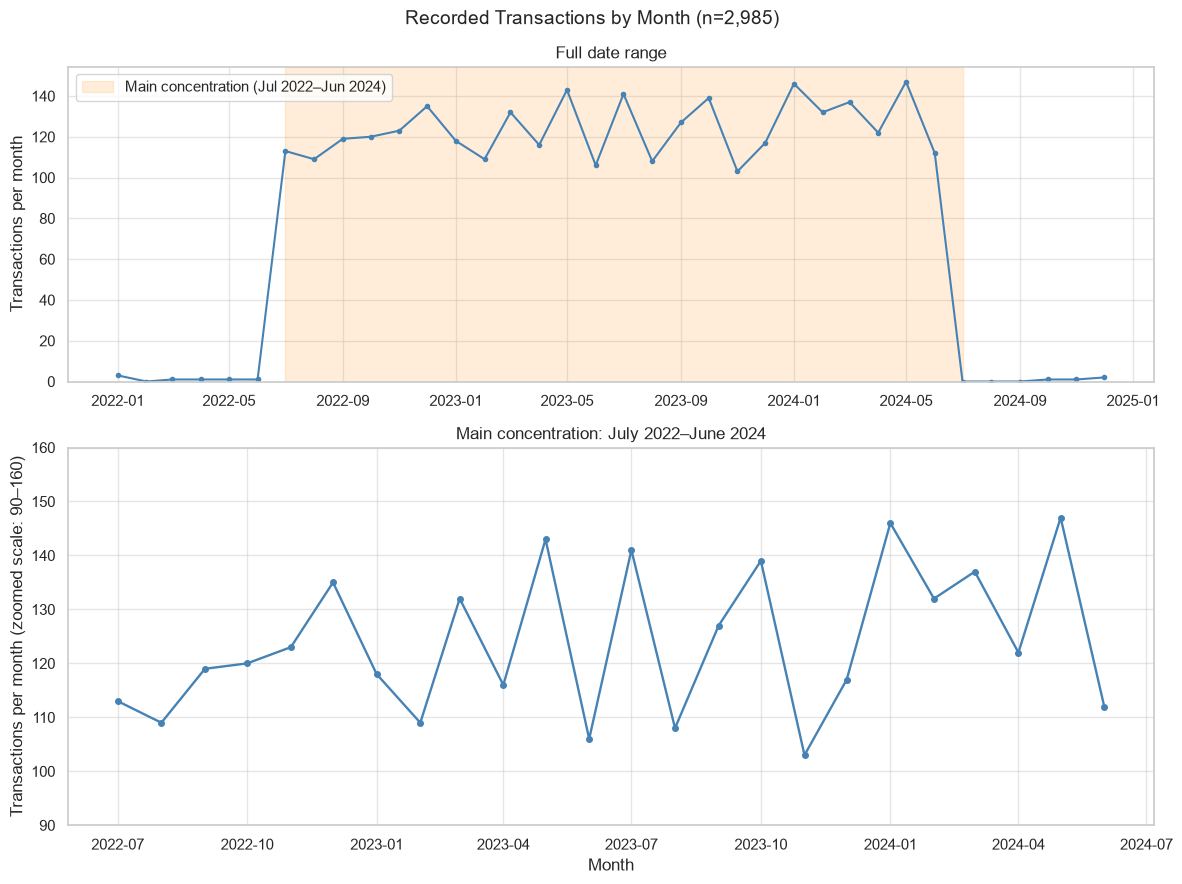

In [34]:
# Show the full date range and zoom in on the main concentration.
all_months = pd.period_range(
    transactions["TransactionDate"].min().to_period("M"),
    transactions["TransactionDate"].max().to_period("M"),
    freq="M",
)

monthly_counts = (
    transactions.dropna(subset=["TransactionDate"])
    .groupby(transactions["TransactionDate"].dt.to_period("M"))
    .size()
    .reindex(all_months, fill_value=0)
)

main_period_start = pd.Period("2022-07", freq="M")
main_period_end = pd.Period("2024-06", freq="M")
main_period_counts = monthly_counts.loc[
    main_period_start:main_period_end
]

fig, (ax_full, ax_main) = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    gridspec_kw={"height_ratios": [1, 1.2]},
)

ax_full.plot(
    monthly_counts.index.to_timestamp(),
    monthly_counts.values,
    marker="o",
    markersize=3,
    linewidth=1.5,
    color="steelblue",
)
ax_full.axvspan(
    main_period_start.start_time,
    (main_period_end + 1).start_time,
    color="darkorange",
    alpha=0.15,
    label="Main concentration (Jul 2022–Jun 2024)",
)
ax_full.set_title("Full date range")
ax_full.set_ylabel("Transactions per month")
ax_full.set_ylim(bottom=0)
ax_full.legend(loc="upper left")

ax_main.plot(
    main_period_counts.index.to_timestamp(),
    main_period_counts.values,
    marker="o",
    markersize=4,
    linewidth=1.7,
    color="steelblue",
)
ax_main.set_title("Main concentration: July 2022–June 2024")
ax_main.set_xlabel("Month")
ax_main.set_ylabel("Transactions per month (zoomed scale: 90–160)")
ax_main.set_ylim(90, 160)

fig.suptitle(
    f"Recorded Transactions by Month (n={monthly_counts.sum():,})",
    fontsize=14,
)
fig.tight_layout()
fig.savefig(
    figures_folder / "05_monthly_transaction_counts.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Monthly Transaction Counts

A line chart was used to show changes in recorded transaction counts
over time. The chart includes 2,985 transactions dated from January 2022
to December 2024.

Most records fall between July 2022 and June 2024. Within this period,
monthly counts range from 103 to 147. May 2024 has the highest count
at 147, while November 2023 has the lowest at 103.

Only 11 transactions fall outside this main period. Their dates were
checked against the original Excel file and matched the source values
as read, so they were retained.

Months shown as zero contain no records in this dataset. This does
not confirm that FinMark had no transactions during those months.
The sharp changes at the edges of the main period cannot establish
business growth or decline because data coverage is uncertain.

For future machine learning, the completeness and consistency of date
coverage should be verified before forecasting or using time trends
to support decisions.

In [22]:
# Inspect social media fields
print("Social media columns:")
print(social_media.columns.tolist())

# Inspect platform and grouped sentiment counts
for column in ["Platform", "SentimentGrouped"]:
    print(f"\n{column}:")
    display(
        social_media[column]
        .fillna("Unknown")
        .value_counts()
        .rename("Count")
        .to_frame()
    )

Social media columns:
['CustomerID', 'InteractionID', 'InteractionDate', 'Platform', 'InteractionType', 'Sentiment', 'IDConflict', 'PlatformOriginal', 'SentimentOriginal', 'SentimentGrouped']

Platform:


,Count
Platform,
Instagram,911
Twitter,897
Facebook,883
Unknown,289



SentimentGrouped:


,Count
SentimentGrouped,
Positive,919
Negative,887
Neutral,867
Unknown,307


SentimentGrouped,Positive,Neutral,Negative,Unknown
Platform,,,,
Instagram,295,255,276,85
Twitter,251,273,271,102
Facebook,270,262,258,93
Unknown,103,77,82,27


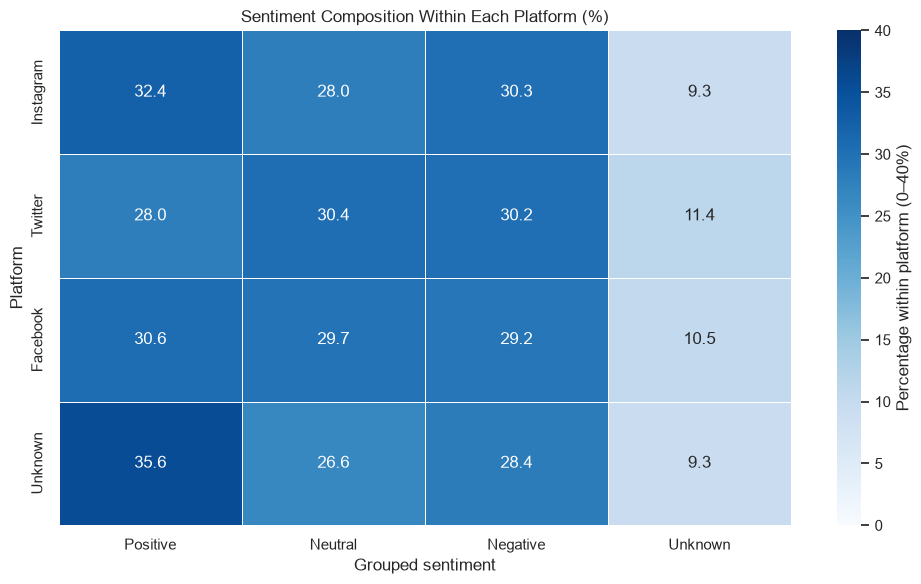

In [38]:
# Count sentiment groups within each platform.
sentiment_counts = pd.crosstab(
    social_media["Platform"].fillna("Unknown"),
    social_media["SentimentGrouped"].fillna("Unknown"),
).reindex(
    index=["Instagram", "Twitter", "Facebook", "Unknown"],
    columns=["Positive", "Neutral", "Negative", "Unknown"],
    fill_value=0,
)

# Each platform row totals 100%.
sentiment_percent = sentiment_counts.div(
    sentiment_counts.sum(axis=1), axis=0
) * 100

display(sentiment_counts)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    sentiment_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=40,
    linewidths=0.5,
    cbar_kws={"label": "Percentage within platform (0–40%)"},
    ax=ax,
)
ax.set_title("Sentiment Composition Within Each Platform (%)")
ax.set_xlabel("Grouped sentiment")
ax.set_ylabel("Platform")
fig.tight_layout()
fig.savefig(
    figures_folder / "06_sentiment_by_platform_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Sentiment Distribution by Platform

A heatmap was used to compare sentiment percentages within each platform
across 2,980 social media interaction records. Each row totals approximately
100%, allowing comparison between platforms with different record counts.

Positive, neutral, and negative sentiments have relatively similar shares
across the three named platforms. Instagram has 32.4% positive sentiment,
Facebook has 30.6%, and Twitter has 28.0%.

Unknown sentiment accounts for 9.3% of Instagram records, 10.5% of Facebook
records, and 11.4% of Twitter records. Unknown represents unavailable
sentiment information and should not be treated as neutral.

The Unknown platform group contains 289 interactions. Its percentages
describe records without an available platform label.

For future machine learning, this chart helps assess sentiment balance
and missing information across platforms. These descriptive differences
do not establish that a platform causes more positive or negative sentiment.

In [39]:
# Verify that demographics has one record per customer
print(
    "Duplicate demographic CustomerIDs:",
    demographics["CustomerID"].duplicated().sum()
)

# Link valid amounts to observed customer ages
age_amount = amount_data.merge(
    demographics[["CustomerID", "AgeObserved"]],
    on="CustomerID",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Valid-amount records:", len(amount_data))
print("Records after linking:", len(age_amount))
print("No matching demographic record:",
      (age_amount["_merge"] == "left_only").sum())
print("Matched but observed age unavailable:",
      ((age_amount["_merge"] == "both")
       & age_amount["AgeObserved"].isna()).sum())

# Keep records with observed ages for the density plot
age_amount = age_amount.dropna(subset=["AgeObserved", "Amount"]).copy()
print("Records available for density plot:", len(age_amount))


Duplicate demographic CustomerIDs: 0
Valid-amount records: 2642
Records after linking: 2642
No matching demographic record: 27
Matched but observed age unavailable: 316
Records available for density plot: 2299


Pearson correlation: 0.0315
Unique customers: 1510


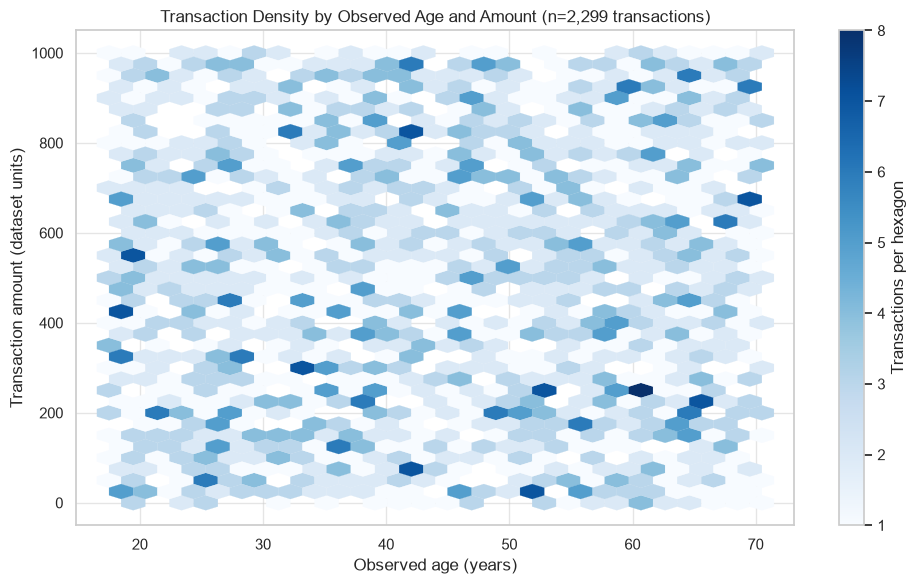

In [40]:
# Calculate descriptive linear correlation and visualize transaction density.
age_amount_r = np.corrcoef(
    age_amount["AgeObserved"].to_numpy(),
    age_amount["Amount"].to_numpy(),
)[0, 1]

print(f"Pearson correlation: {age_amount_r:.4f}")
print("Unique customers:", age_amount["CustomerID"].nunique())

fig, ax = plt.subplots(figsize=(10, 6))
density = ax.hexbin(
    age_amount["AgeObserved"],
    age_amount["Amount"],
    gridsize=(27, 20),
    mincnt=1,
    cmap="Blues",
    linewidths=0.15,
    extent=(17.5, 70.5, 0, 1000),
)
fig.colorbar(density, ax=ax, label="Transactions per hexagon")

ax.set_title(
    f"Transaction Density by Observed Age and Amount "
    f"(n={len(age_amount):,} transactions)"
)
ax.set_xlabel("Observed age (years)")
ax.set_ylabel("Transaction amount (dataset units)")
fig.tight_layout()
fig.savefig(
    figures_folder / "07_age_vs_transaction_amount.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Customer Age and Transaction Amount

A hexbin density plot shows how transaction amounts are distributed across
observed customer ages. Each hexagon represents the number of transactions
within an age-and-amount interval, making dense regions easier to see than
overlapping individual points.

Transactions were linked to demographics using CustomerID. The analysis
includes 2,299 transactions from 1,510 customers with both an observed
age and a valid amount. Of the 2,642 amount records, 27 had no matching
demographic record and 316 matched records without an observed age.

The hexagons are spread across the age and amount ranges, with no clear
upward or downward linear pattern. The Pearson correlation is approximately
0.0315, indicating very little linear association in this analysis subset.

Some customers contribute multiple transactions, so the counts are
transaction counts rather than independent customer observations.

For future machine learning, this result suggests that age alone has
little linear association with individual transaction amount. It does
not rule out nonlinear relationships or usefulness alongside other
variables, which would require further evaluation.


## Additional EDA Comparisons

These figures extend the existing charts with a categorical relationship, an age comparison across demographic groups, and a data-quality view of transaction amounts. Amount statuses are shown separately so missing, nonnumeric, negative, and zero values are not conflated. The existing amount-by-category boxplot remains the visual check for potential outliers; the NumPy IQR calculation found none in the selected amount subset.

ProductCategory,Automotive,Clothing,Electronics,Health & Beauty,Home & Garden,Unknown
PaymentMethod,,,,,,
Bank Transfer,127,137,138,126,140,65
Credit Card,130,149,132,146,125,69
Debit Card,128,150,153,122,144,60
PayPal,151,129,135,126,119,84


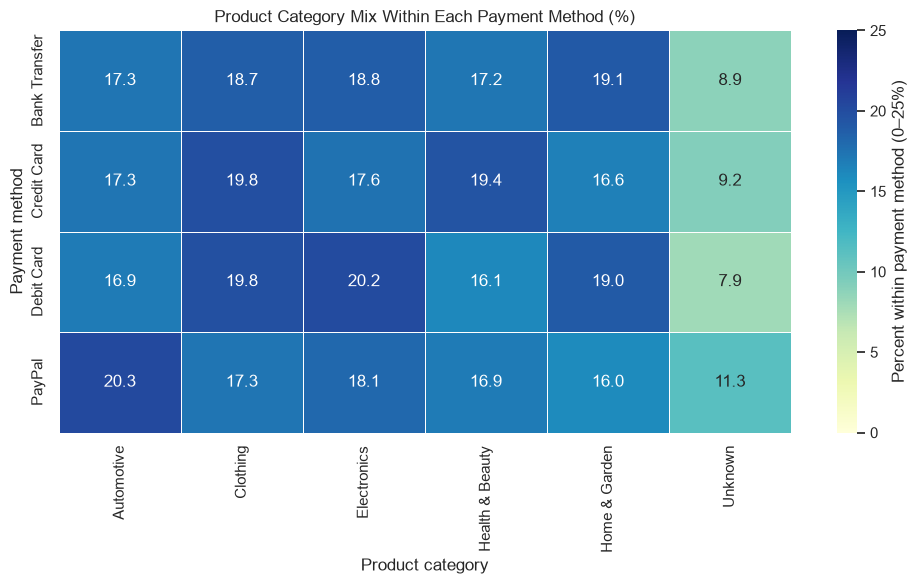

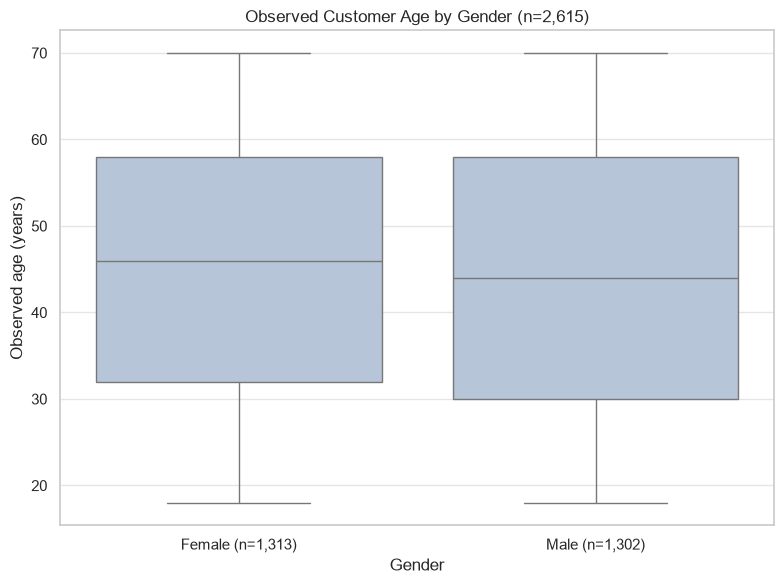

,Count,Percent of all transactions
AmountStatus,,
Positive numeric,2614,87.571189
Zero: retained,28,0.938023
Missing,281,9.413735
Non-numeric: review,29,0.971524
Negative: review,33,1.105528


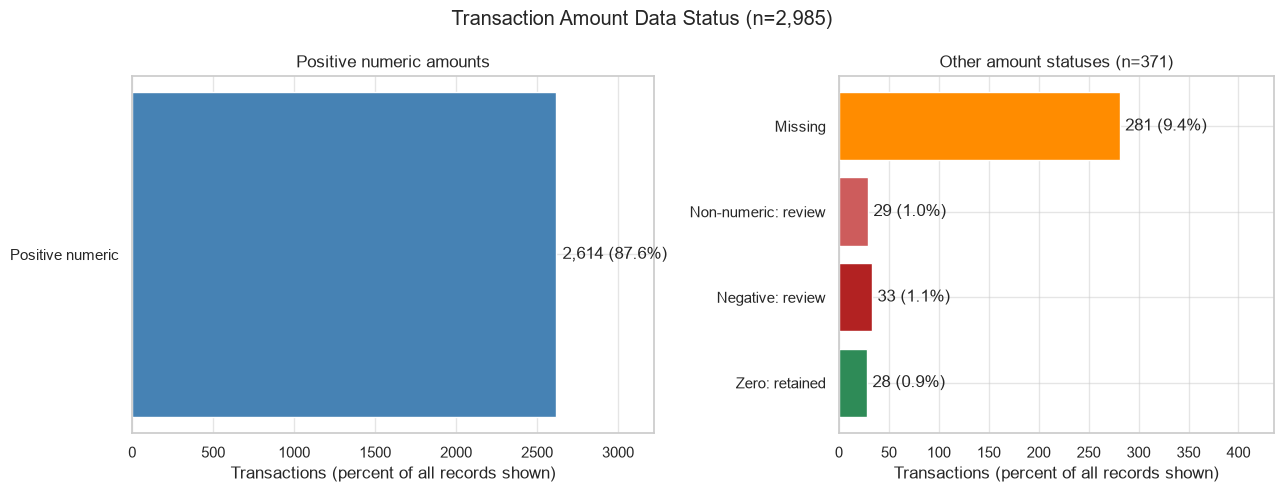

In [41]:
# Payment method vs product category: compare category shares within each method.
payment_category_counts = pd.crosstab(
    transactions["PaymentMethod"].fillna("Unknown"),
    transactions["ProductCategory"].fillna("Unknown"),
)
payment_category_percent = payment_category_counts.div(
    payment_category_counts.sum(axis=1), axis=0
) * 100

display(payment_category_counts)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    payment_category_percent,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=25,
    linewidths=0.5,
    cbar_kws={"label": "Percent within payment method (0–25%)"},
    ax=ax,
)
ax.set_title("Product Category Mix Within Each Payment Method (%)")
ax.set_xlabel("Product category")
ax.set_ylabel("Payment method")
fig.tight_layout()
fig.savefig(
    figures_folder / "08_payment_method_by_product_category.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Compare observed ages by gender; imputed ages are excluded.
age_by_gender = demographics.dropna(
    subset=["AgeObserved", "Gender"]
).copy()
gender_order = sorted(age_by_gender["Gender"].unique())
gender_counts = age_by_gender.groupby("Gender", observed=True).size()

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(
    data=age_by_gender,
    x="Gender",
    y="AgeObserved",
    order=gender_order,
    color="lightsteelblue",
    showfliers=True,
    ax=ax,
)
ax.set_xticks(
    range(len(gender_order)),
    [f"{gender} (n={gender_counts[gender]:,})" for gender in gender_order],
)
ax.set_title(
    f"Observed Customer Age by Gender (n={len(age_by_gender):,})"
)
ax.set_xlabel("Gender")
ax.set_ylabel("Observed age (years)")
fig.tight_layout()
fig.savefig(
    figures_folder / "09_observed_age_by_gender.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Separate the large positive-numeric group from smaller statuses
# so missing and review counts remain visible.
amount_status_order = [
    "Numeric",
    "Zero: retained",
    "Missing",
    "Non-numeric: review",
    "Negative: review",
]
amount_status_counts = (
    transactions["AmountStatus"]
    .value_counts()
    .reindex(amount_status_order, fill_value=0)
    .rename(index={"Numeric": "Positive numeric"})
)
amount_status_percent = amount_status_counts / len(transactions) * 100
display(pd.DataFrame({
    "Count": amount_status_counts,
    "Percent of all transactions": amount_status_percent,
}))

positive_numeric = amount_status_counts.loc["Positive numeric"]
other_status_order = [
    "Missing",
    "Non-numeric: review",
    "Negative: review",
    "Zero: retained",
]
other_status_counts = amount_status_counts.reindex(other_status_order)
other_records = int(other_status_counts.sum())

fig, (ax_valid, ax_other) = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    gridspec_kw={"width_ratios": [1.2, 1]},
)
valid_bar = ax_valid.barh(
    ["Positive numeric"],
    [positive_numeric],
    color="steelblue",
)
ax_valid.bar_label(
    valid_bar,
    labels=[f"{positive_numeric:,} ({amount_status_percent['Positive numeric']:.1f}%)"],
    padding=5,
)
ax_valid.set_xlim(0, len(transactions) * 1.08)
ax_valid.set_title("Positive numeric amounts")
ax_valid.set_xlabel("Transactions (percent of all records shown)")

other_bars = ax_other.barh(
    other_status_counts.index,
    other_status_counts.values,
    color=["darkorange", "indianred", "firebrick", "seagreen"],
)
ax_other.invert_yaxis()
ax_other.bar_label(
    other_bars,
    labels=[
        f"{count:,} ({amount_status_percent[status]:.1f}%)"
        for status, count in other_status_counts.items()
    ],
    padding=4,
)
ax_other.set_xlim(0, max(other_status_counts.max(), 1) * 1.55)
ax_other.set_title(f"Other amount statuses (n={other_records:,})")
ax_other.set_xlabel("Transactions (percent of all records shown)")

fig.suptitle(
    f"Transaction Amount Data Status (n={len(transactions):,})"
)
fig.tight_layout()
fig.savefig(
    figures_folder / "10_transaction_amount_data_status.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Interpretation of the Additional Comparisons

The payment-method heatmap shows similar shares across the five named product categories, generally around 16%–20% within each payment method. Unknown product categories account for about 7.9%–11.3% per method. The earlier Cramer’s V of 0.0436 indicates weak association in this subset; the chart does not establish independence.

The observed-age boxplots overlap substantially by gender. The female median is 46 and the male median is 44 in this subset; both groups span ages 18–70. This is a descriptive comparison and does not imply that gender explains age or any transaction behavior.

The amount-status chart shows 2,614 numeric nonzero amounts, 28 retained zero amounts, 281 missing amounts, 29 nonnumeric values, and 33 negative values. The amount-by-category boxplot and NumPy IQR results show no potential amount outliers under the 1.5 × IQR rule. The flagged amount statuses still warrant review; the IQR result does not verify transaction accuracy.

In [42]:
# Check exported chart files
chart_files = sorted(figures_folder.glob("*.png"))

print("Exported charts:", len(chart_files))
for file in chart_files:
    print(file.name)

Exported charts: 10
01_observed_age_distribution.png
02_transaction_amount_distribution.png
03_product_category_counts.png
04_amount_by_product_category.png
05_monthly_transaction_counts.png
06_sentiment_by_platform_heatmap.png
07_age_vs_transaction_amount.png
08_payment_method_by_product_category.png
09_observed_age_by_gender.png
10_transaction_amount_data_status.png


## Interpretation of Visualizations and Numerical Results

The findings below describe the selected EDA subsets: 2,977 demographic records, 2,985 transaction records, and 2,980 social media records. Age statistics use observed ages (n=2,615); transaction amount statistics use nonmissing, nonnegative amounts, including zero (n=2,642). Unresolved ID conflicts are excluded from these EDA datasets.

### 1. Observed Age Distribution and NumPy Statistics

Observed ages range from 18 to 70, with mean 44.59, median 45, sample standard deviation 15.42, and variance 237.81. Skewness is close to zero (-0.059), while excess kurtosis is -1.220, indicating a flatter distribution than a normal distribution under the moment measure used here. Age-band counts are 584 (18–29), 466 (30–39), 476 (40–49), 513 (50–59), and 576 (60–70); the youngest and oldest bands are largest in this sample. The observed mode is 62, while the median is 45.

The IQR rule flags no potential age outliers. This does not validate every age or explain why an age was unavailable. There are 362 records in the demographics EDA subset without an eligible observed age; analyses should preserve that missingness signal. For modeling, fit any age imputation using training data only and consider evaluating performance across age groups.

### 2. Transaction Amount Distribution and NumPy Statistics

For 2,642 nonnegative amounts, the mean is 499.03, median 503.66, sample standard deviation 292.46, and variance 85,533.17. Values range from 0 to 999.86. The ten equal-width bins contain fairly similar counts (about 9.2%–10.9% each). Skewness is near zero (0.015), and excess kurtosis is -1.207; the amounts do not show a strong right tail in this selected subset. The mean and median being close does not prove that the data is unbiased or truly uniform.

The 1.5 × IQR rule flags no potential amount outliers overall. The 28 zero amounts are retained and included; see the separate amount-status chart. Keep the amount analysis subset definition explicit, and decide how to treat zero and review values based on the business meaning before modeling.

### 3. Transaction Counts by Product Category

Among 2,985 transactions, named categories range from 520 Health & Beauty records to 565 Clothing records; Electronics has 558, Automotive 536, and Home & Garden 528. The named categories are relatively similar in frequency, with no single category dominating. There are 278 Unknown product categories (9.3%).

For modeling, keep Unknown distinct from a known product category unless the business definition supports merging it. Check category counts in each training/test split before encoding.

### 4. Transaction Amounts by Product Category

Home & Garden has the highest median amount (524.62), followed by Automotive (519.57), Electronics (510.75), Clothing (507.66), Health & Beauty (466.14), and Unknown (461.82). The boxplots show substantial spread within each category and overlapping ranges, so the median differences alone do not establish a meaningful category effect.

No category has potential outliers under its own 1.5 × IQR fences. Product category may be worth evaluating as a feature, but its predictive value needs to be tested on held-out data; the descriptive medians do not establish causation.

### 5. Monthly Transaction Counts

The full-range panel shows that records are concentrated from July 2022 through June 2024, with very few records outside that interval. Within the main period, monthly counts range from 103 (November 2023) to 147 (May 2024). The two-panel chart makes both the uneven coverage and the variation within the main period visible.

Empty or sparse months may reflect data coverage rather than actual business inactivity. Verify date completeness before treating monthly counts as a business trend or building forecasting features. A future time-based model should use chronological validation rather than a random split.

### 6. Sentiment Composition by Platform

Within Instagram, Twitter, and Facebook, Positive, Neutral, and Negative sentiment each account for roughly 28%–32% of records. Their percentages are similar across the three named platforms; Unknown sentiment ranges from about 9.3% to 11.4%. There are also 289 interactions whose platform is Unknown.

The heatmap supports comparison of sentiment mix by platform but does not show that platform causes sentiment. Keep Unknown separate from Neutral. If sentiment is a future prediction target, avoid including the target itself or fields derived from it as predictors.

### 7. Observed Age Versus Transaction Amount

The hexbin density chart contains 2,299 transactions from 1,510 customers with both an observed age and valid amount. Hexagons show counts within age-and-amount intervals, reducing overlap from repeated integer ages. The distribution spans broadly across the plotted ranges, and Pearson correlation is about 0.0315, indicating very little linear association in this subset. Some customers contribute multiple transactions, so hexagon counts are transactions rather than independent customer observations.

Age alone shows little linear relationship with transaction amount here. For future modeling, consider whether customer-level aggregation is appropriate and keep transactions from the same customer together when splitting data to reduce leakage.

### 8. Payment Method by Product Category

Within each payment method, the five named product-category shares are mostly around 16%–20%; Unknown product shares range from about 7.9% to 11.3%. Cramer's V is 0.0436, indicating weak association in this subset. The heatmap is useful for checking the comparison, but it does not prove independence or rule out other relationships.

There is no strong imbalance among the named categories in this cross-tabulation. Treat the result as descriptive; evaluate feature interactions with an appropriate validation design if they matter to a model.

### 9. Observed Age by Gender

The observed-age boxplots overlap substantially. Female records have median age 46 (n=1,313), and male records have median age 44 (n=1,302); both groups span 18–70. The two-year median difference is descriptive and does not establish that gender explains age or transaction behavior.

For future models, assess performance and error rates by demographic group where appropriate. Do not infer fairness from similar group sizes or from this age comparison alone.

### 10. Transaction Amount Data Status

Of 2,985 transaction EDA records, 2,614 have numeric nonzero amounts (87.6%), 28 have a retained zero (0.9%), 281 are missing (9.4%), 29 are nonnumeric (1.0%), and 33 are negative (1.1%). The chart separates unavailable and review values from valid zeros so they are not conflated.

Missing, nonnumeric, and negative values are potential data-quality concerns even though the valid-amount IQR analysis flags no outliers. Review negative amounts against the transaction definition. For modeling, define a consistent handling policy and fit imputation or transformation steps on training data only.

### Overall Implications for Future Machine Learning

These figures describe the current EDA samples; they do not establish causation, forecastability, or model performance. Before modeling, define a target and prediction unit, resolve or explicitly handle flagged records, check date and missingness coverage, encode categorical values consistently, and fit preprocessing only on training data. Use customer-aware or time-aware splits where the prediction task requires them, and evaluate subgroup performance when relevant.


## Prioritized actions before machine learning

1. **Define the prediction task.** Agree on the target, prediction unit (customer, transaction, or interaction), decision date, and what action a prediction will support. The current EDA does not select a target.
2. **Confirm data meaning and coverage.** Use a data dictionary or domain owner to resolve zero and negative amounts, missing/non-numeric fields, Unknown categories, ID conflicts, and sparse dates. Record the final inclusion rules.
3. **Prevent information leakage.** Choose a split that matches the task: keep each customer's records together when predicting for new customers, or use chronological validation for future outcomes. Fit imputers, scalers, and encoders on training data only.
4. **Establish a baseline and evaluate it.** Compare a simple baseline with candidate models on held-out data using task-appropriate metrics. Review errors by relevant demographic and data-quality groups before recommending use.

These steps turn the descriptive findings into a reviewable modeling plan. They are recommendations, not evidence that a model has been built or validated.